# RTENSO2026 El Nino cases: anomaly maps and pattern ACC

Case-study companion to ESP-Lab `1a_*_leadtime_acc_skill_map.ipynb` and
`1b_*_leadtime_rmse_skill_map.ipynb`, for each event in `EVENTS` (the 2015/16 El Nino
from the 2015 Feb/May/Aug/Nov starts and the 2026/27 El Nino from the 2026 Feb/May/Aug
starts). With one target year, the ACC is the **spatial** anomaly correlation
(area-weighted, centred) between the forecast and observed anomaly maps, computed per
lead season, per member and for the ensemble mean, over several regions; the RMSE is the
matching area-weighted map error.

Anomalies remove the Reanalysis 1981-2010 lead-time climatology (drift-corrected,
`CLIM_METHOD = "start_drift"`; see the README) and each product's 1981-2010 observed monthly
climatology. `TS` is verified against HadISST 1.1 over ice-free ocean (60S-60N), with the
ensemble-mean ACC against ERSSTv5 and ESA CCI SST for comparison; `PRECT` against GPCP
v2.3; `TREFHT`, `PSL` and `U850` against ERA5, which ends in 2019, so those fields cover
2015 only. Only lead seasons whose three months are all observed are scored, so the 2026
starts are verified through summer 2026 and the DJF 2026/27 maps show forecasts only.

**1 Feb 2026 start:** `Reanalysis-CLIM` and `Reanalysis-OBS` started from the same BruteForce 2010 land/river/sea-ice state and are bit-identical, so their curves/maps coincide (see "1 Feb 2026 start" in `README.md`).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from matplotlib.colors import BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from cartopy.util import add_cyclic_point
from esp_lab.utils import colormap_utils as mycolors
from esp_lab.utils.netcdf_utils import atomic_to_netcdf

import sys
from pathlib import Path
# diagnostic/ (the shared util package) is the first parent folder holding util/rtenso_case.py
DIAG_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util" / "rtenso_case.py").is_file())
sys.path.insert(0, str(DIAG_ROOT))
from util import rtenso_case as rc

warnings.filterwarnings("ignore", message="invalid value encountered")   # ACC/RMSE of unobserved seasons are NaN

In [2]:
def to_datetime(times):
    return [datetime(t.year, t.month, 15) for t in np.atleast_1d(times)]


def map_cmap(name, ci, cmin, cmax):
    if name == "blue2red":
        cmap = mycolors.blue2red_cmap(np.arange(cmin, cmax + ci, ci))
    else:
        cmap = plt.get_cmap(name)
    return cmap

### Run controls

In [3]:
NOTEBOOK = "enso/02_anomaly_maps_acc"   # outputs: rc.OUTPUT_ROOT/enso/02_anomaly_maps_acc/{figures,data}/
FORCE_COMPUTE = False   # False: read valid caches, build missing or stale ones; True: recompute this notebook's products
                        # (shared Reanalysis/observation/ERA5 caches are reused; set rc.REBUILD_REFERENCE = True to redo them)
derivation_mode = "rebuild" if FORCE_COMPUTE else "auto"
CLIM_METHOD = "start_drift"         # drift correction: "start_drift" (default); "lead_drift", "direct", "target_month" for sensitivity

FIELD = "TS"                       # TS, PRECT (2015 and 2026); TREFHT, PSL, U850 (2015 only: ERA5 ends in 2019)
MONTH_NAMES = {2: "Feb", 5: "May", 8: "Aug", 11: "Nov"}

# Observations. OBS_REFERENCE[FIELD] verifies the forecasts (missing: rc default with its archive
# fallback); OBS_COMPARE[FIELD] are products whose ensemble-mean ACC is also drawn, for comparison.
OBS_REFERENCE = {"TS": "HadISST1.1"}
OBS_COMPARE = {"TS": ("ERSSTv5", "ESA_CCI_SST")}
OBS_COMPARE_LS = {"ERSSTv5": "--", "ESA_CCI_SST": ":"}

MAP_STYLE = {
    # field: (contour interval, min, max, colormap)
    "TS": (0.25, -3.0, 3.0, "blue2red"),
    "TREFHT": (0.25, -3.0, 3.0, "blue2red"),
    "PRECT": (0.5, -5.0, 5.0, "BrBG"),
    "PSL": (0.5, -6.0, 6.0, "blue2red"),
    "U850": (0.5, -6.0, 6.0, "blue2red"),
}

# Events and hindcast cases: the shared registry in util/rtenso_case.py (rc.EVENTS, rc.CASES). A case is
# used only for the starts it has (rc.has_start: Reanalysis-FOSIRL has no 2026 run).
EVENTS = rc.EVENTS
CASES = rc.CASES
ACC_REGIONS = ["Global", "Tropics", "TropPacific", "NHextratropics", "NorthAmerica"]

OUTDIR = rc.output_dir(NOTEBOOK, "data", FIELD)
OUTDIR.mkdir(parents=True, exist_ok=True)

### Load anomalies

In [4]:
%%time
reference = OBS_REFERENCE.get(FIELD)
obs, anoms = {}, {}   # year -> observed anomalies; (year, case, init) -> (anomaly, matched obs, {product: matched obs})
for year, event in EVENTS.items():
    try:
        obs[year] = rc.obs_anomaly(FIELD, years=(year, year + 2), mode=derivation_mode, product=reference)
    except ValueError as err:   # e.g. no ERA5 TREFHT/PSL/U850 after 2019
        print(f"[{year}] skipped: {err}")
        continue
    compare = {p: rc.obs_anomaly(FIELD, years=(year, year + 2), mode=derivation_mode, product=p)
               for p in OBS_COMPARE.get(FIELD, ())}
    observed_months = obs[year]["time"].values[obs[year].notnull().any(("lat", "lon")).values]
    print(f"[{year}] {obs[year].attrs['product']} observed through {observed_months[-1].year}-{observed_months[-1].month:02d}")
    # SST: ice-free ocean within 60S-60N; months not yet observed use the points ice-free in every observed month
    ice_free = obs[year].notnull().all("time")

    for case in CASES:
        for init in event["init_months"]:
            if not rc.has_start(case, year, init):
                continue
            anom = rc.hindcast_anomaly(CASES[case]["case_prefix"], init, FIELD, year=year,
                                       method=CLIM_METHOD, mode=derivation_mode)
            if anom is None:
                print(f"[{year} {case} init{init:02d}] not available")
                continue
            obs_matched = rc.match_obs(anom, obs[year])   # NaN past the last observation
            compare_matched = {p: rc.match_obs(anom, o) for p, o in compare.items()}
            if FIELD == "TS":
                observed = obs_matched.notnull().any(("lat", "lon"))
                mask = xr.where(observed, obs_matched.notnull(), ice_free) & (abs(obs_matched["lat"]) <= 60.0)
                anom, obs_matched = anom.where(mask), obs_matched.where(mask)
                compare_matched = {p: o.where(mask) for p, o in compare_matched.items()}
            anoms[(year, case, init)] = (anom, obs_matched, compare_matched)
            print(f"[{year} {case} init{init:02d}] {anom.sizes['member']} members; {anom.attrs['climatology_method']}")

[2015] HadISST1.1 observed through 2017-12


[2015 Reanalysis-CLIM init02] 10 members; HadISST1.1 1981-2010 target-month climatology + Reanalysis init02 drift over 6 starts (1985-2010; start_drift)


[2015 Reanalysis-CLIM init05] 10 members; HadISST1.1 1981-2010 target-month climatology + Reanalysis init05 drift over 30 starts (1981-2010; start_drift)


[2015 Reanalysis-CLIM init08] 10 members; HadISST1.1 1981-2010 target-month climatology + Reanalysis init08 drift over 6 starts (1985-2010; start_drift)


[2015 Reanalysis-CLIM init11] 10 members; HadISST1.1 1981-2010 target-month climatology + Reanalysis init11 drift over 30 starts (1981-2010; start_drift)


[2015 Reanalysis-OBS init02] 10 members; HadISST1.1 1981-2010 target-month climatology + Reanalysis init02 drift over 6 starts (1985-2010; start_drift)


... (20 outputs left out)

[2026 Reanalysis-NSIDC init02] 10 members; HadISST1.1 1981-2010 target-month climatology + Reanalysis init02 drift over 6 starts (1985-2010; start_drift)


[2026 Reanalysis-NSIDC init05] 10 members; HadISST1.1 1981-2010 target-month climatology + Reanalysis init05 drift over 30 starts (1981-2010; start_drift)


[2026 Reanalysis-NSIDC init08] 10 members; HadISST1.1 1981-2010 target-month climatology + Reanalysis init08 drift over 6 starts (1985-2010; start_drift)


[2026 Reanalysis-NSIDC init11] 10 members; HadISST1.1 1981-2010 target-month climatology + Reanalysis init11 drift over 30 starts (1981-2010; start_drift)
CPU times: user 13.1 s, sys: 9.69 s, total: 22.8 s
Wall time: 3min 23s


### Focus-season anomaly maps

Ensemble-mean anomalies over each event's focus season from every start, with the global pattern ACC in each title when the season is observed.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/2_anomaly_maps_acc/figures/fig_rtenso2026_anomaly_map_ts_y2015_djf_201516.png


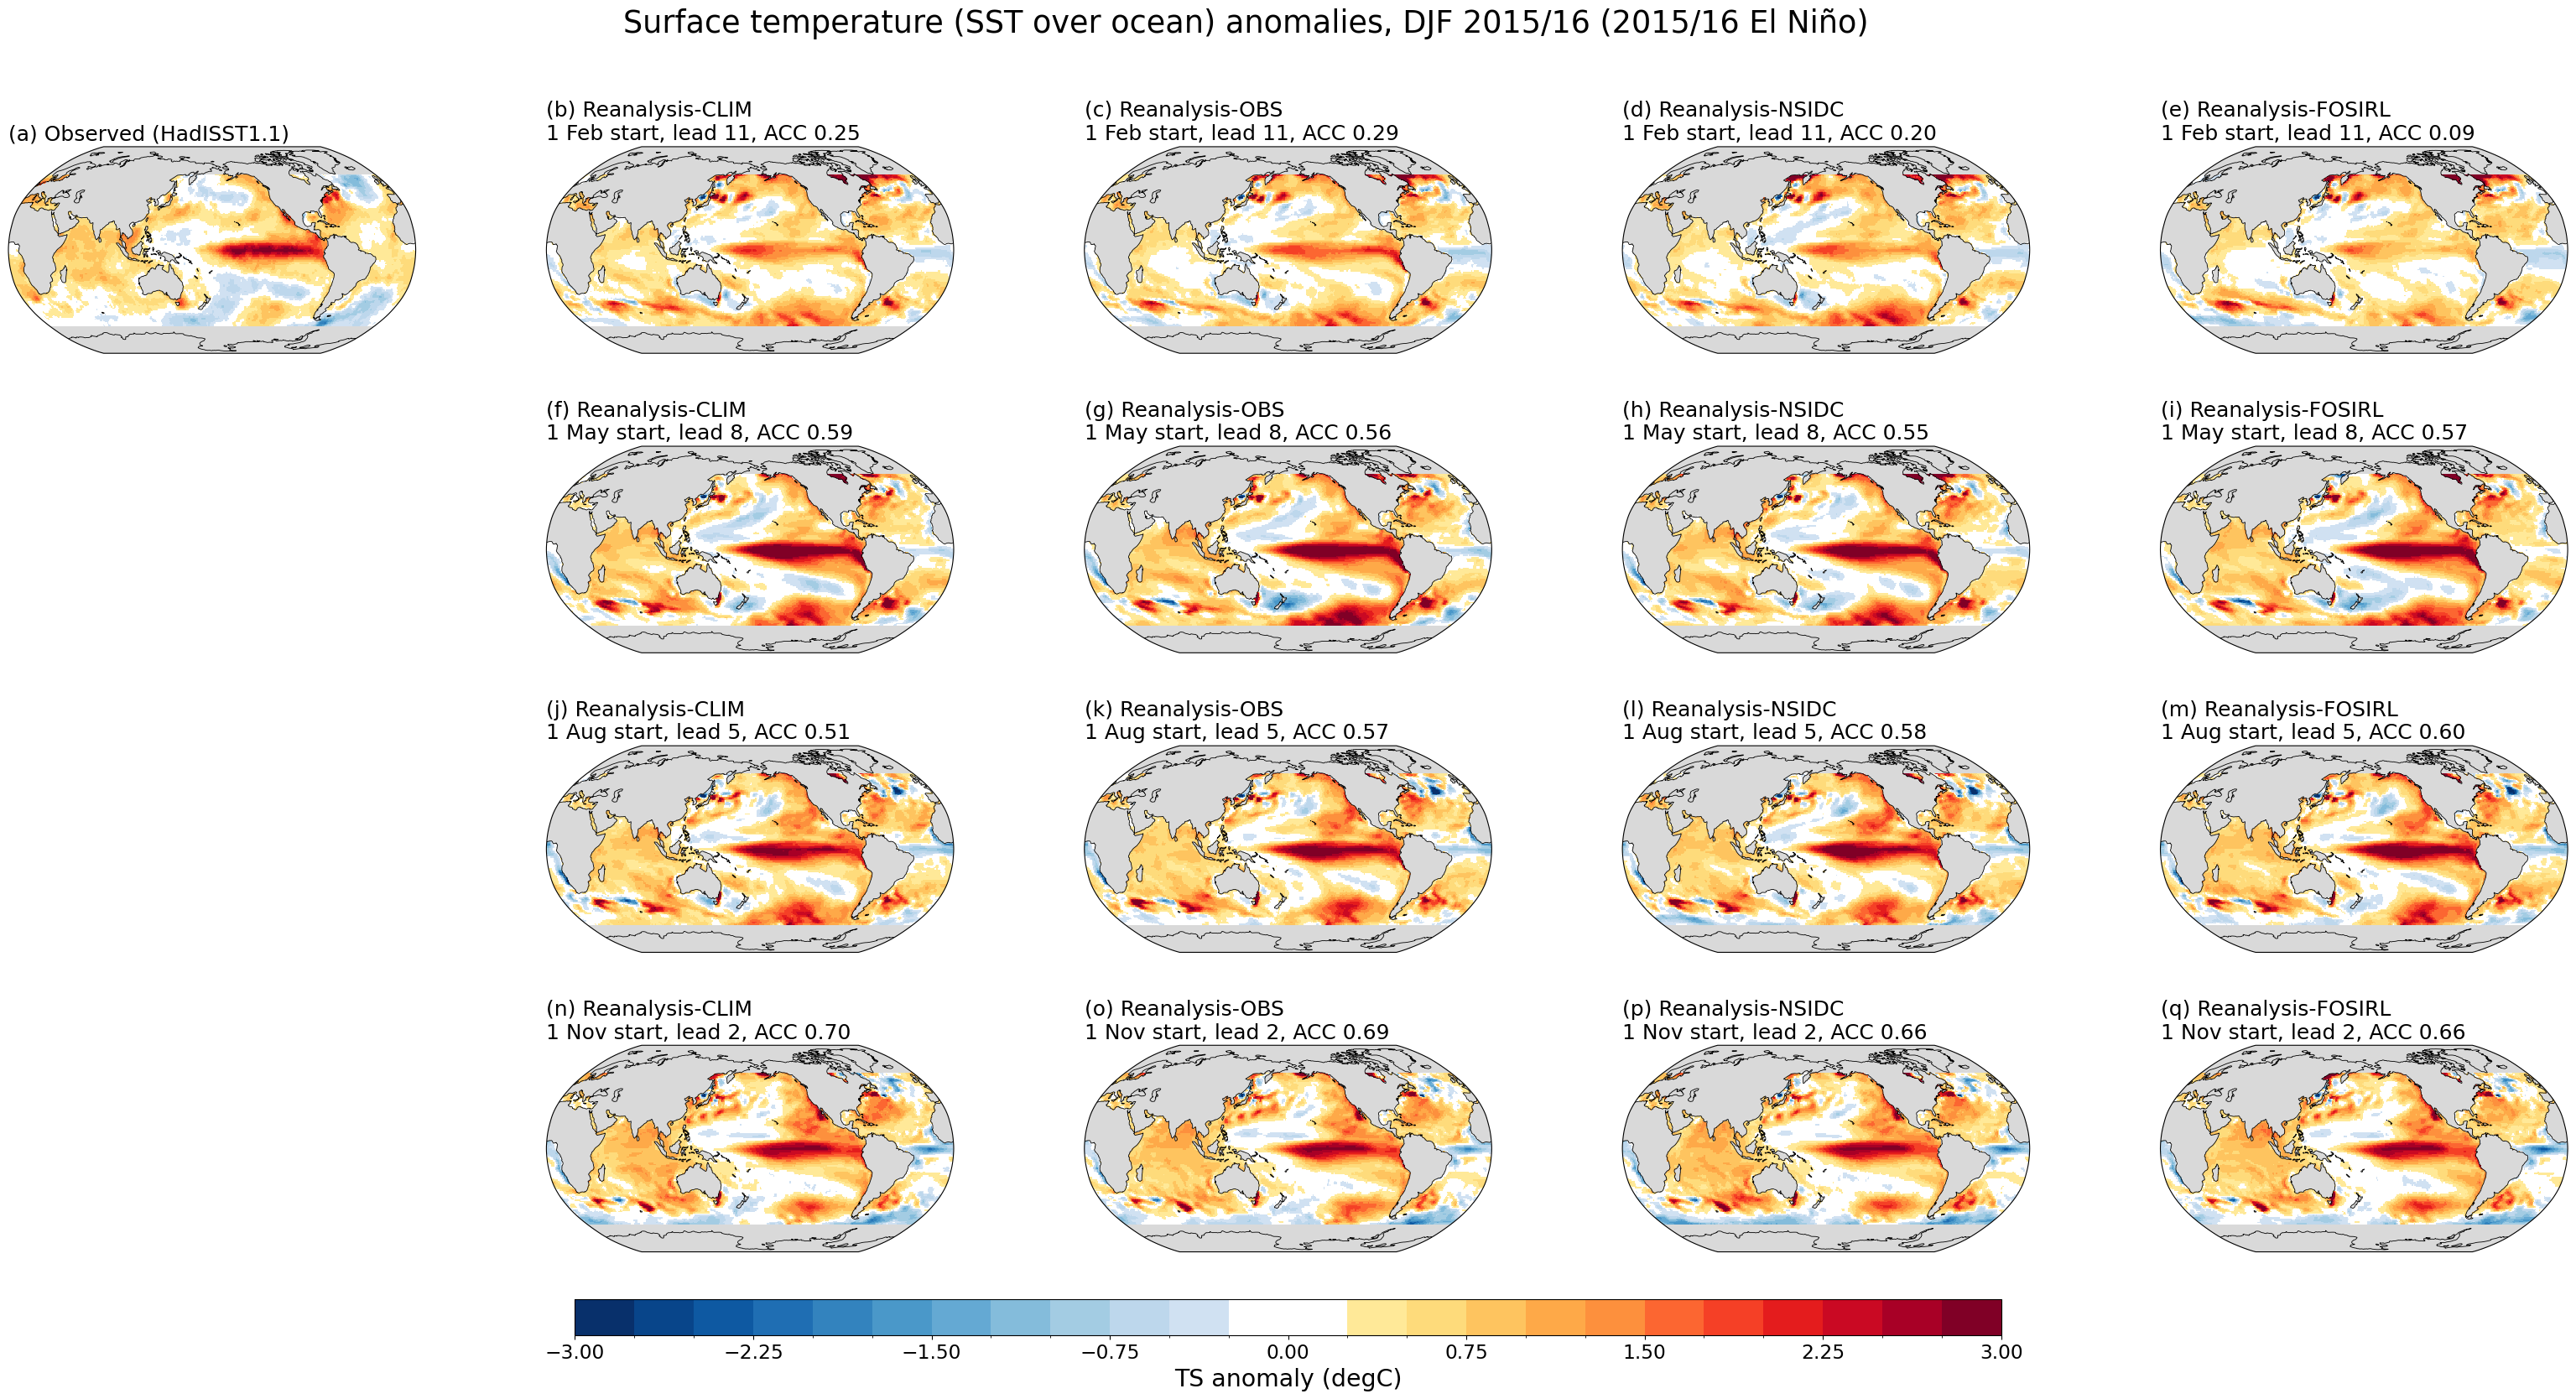

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/2_anomaly_maps_acc/figures/fig_rtenso2026_anomaly_map_ts_y2026_djf_202627.png


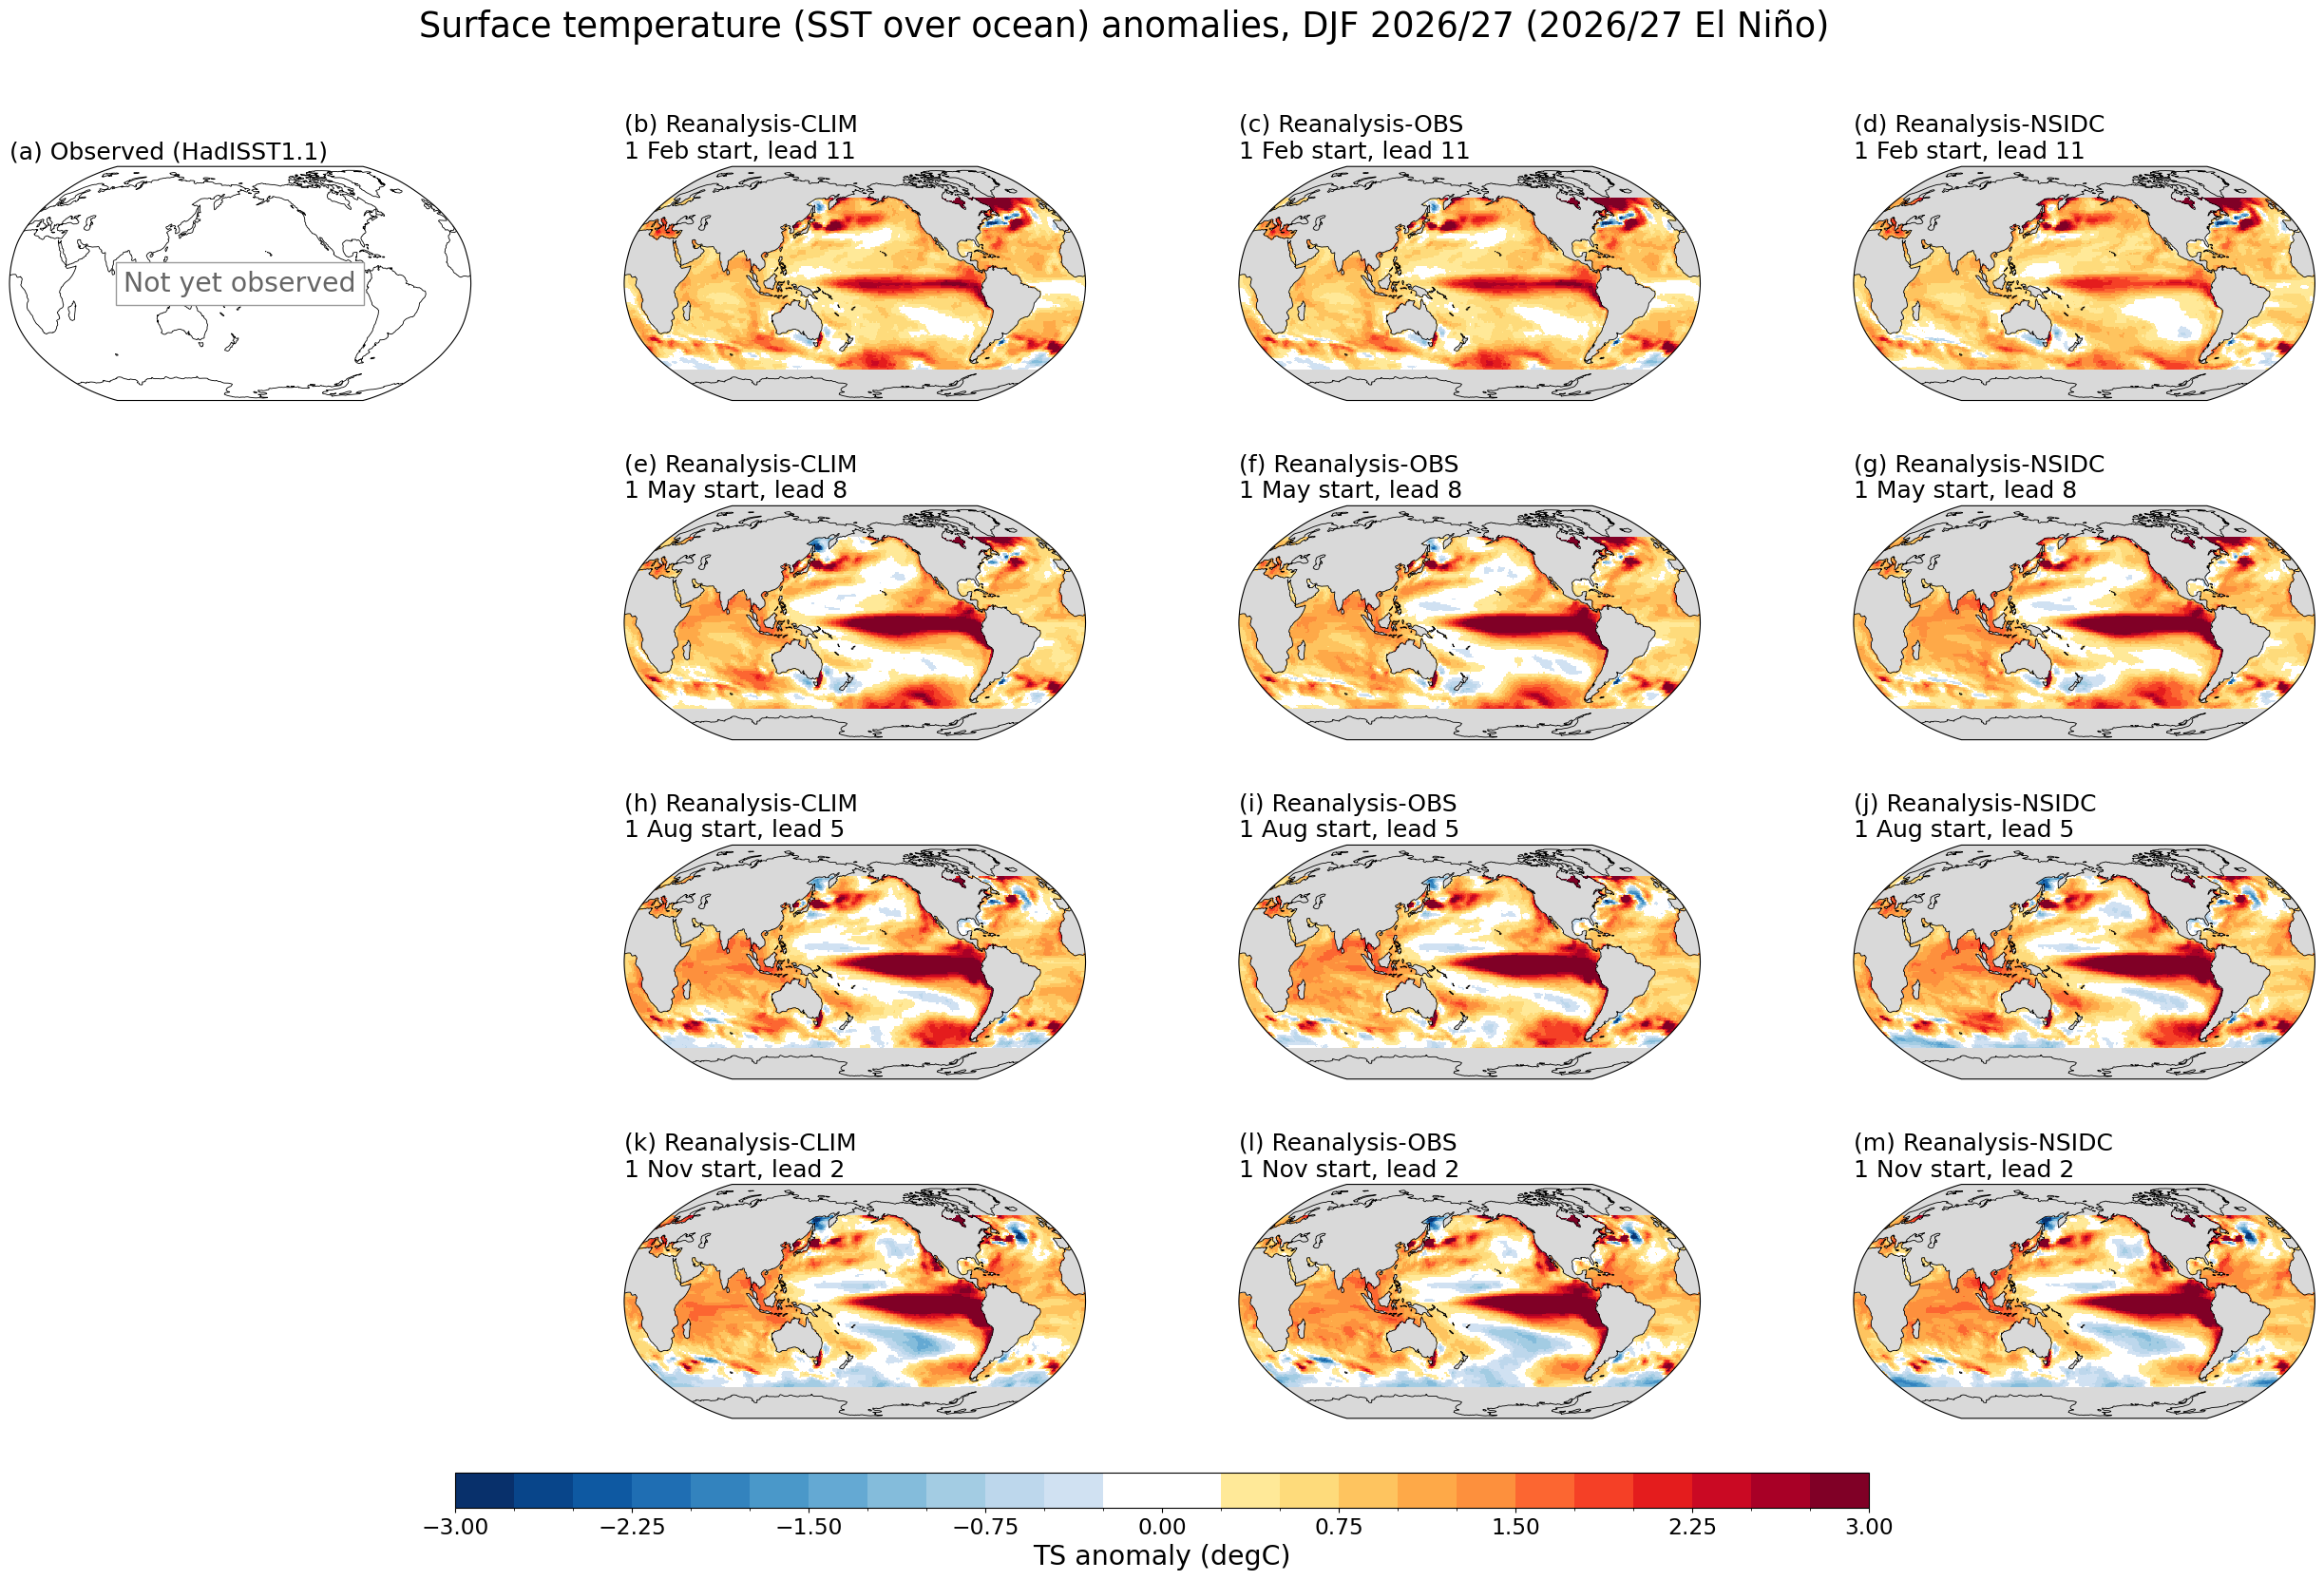

In [5]:
# ---- Figure setup (also used by the ACC/RMSE figures below) ----
fontz = 24        # base font size; every other size scales from it
fig_type = "png"  # saved figure type: "png", "pdf" (vector), "eps", "svg", ...
fig_dpi = 300     # resolution of saved raster figures
FIG = {
    "map_panel": (8.0, 4.6),        # inches per map panel (width, height)
    "map_hspace": 0.45,             # vertical gap between map rows (fraction of a panel height)
    "map_top": 0.88,                # top of the map panels (figure fraction); the suptitle sits above
    "map_suptitle_y": 0.97,         # suptitle height on the map figures (figure fraction)
    "metric_panel": (7.5, 4.5),     # inches per ACC/RMSE panel
    "suptitle": fontz * 1.1,
    "title": fontz * 0.75,          # panel titles
    "label": fontz * 0.85,          # axis and colorbar labels
    "tick": fontz * 0.7,
    "legend": fontz * 0.8,
    "legend_ncol": 4,
    "legend_box": {"frameon": True, "fancybox": False, "edgecolor": "0.3", "framealpha": 1.0,
                   "borderpad": 0.8, "columnspacing": 2.0},
    "suptitle_y": 1.02,
    "coast_lw": 0.6,
    "ens_lw": 3.5,
    "compare_lw": 2.0,
    "marker_size": 10,
    "member_alpha": 0.2,
}
PANEL_LETTERS = "abcdefghijklmnopqrstuvwxyz"


def save_fig(fig, *parts):
    print(rc.save_figure(fig, NOTEBOOK, *parts, dpi=fig_dpi, ext=fig_type))


def add_bottom_legend(fig, handles, labels, y=0.0):
    legend = fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, y), ncol=FIG["legend_ncol"],
                        fontsize=FIG["legend"], **FIG["legend_box"])
    legend.get_frame().set_linewidth(1.2)


def draw_map(fig, da, nrow, ncol, index, title, field):
    """Robinson map in the ESP-Lab style; NaN (e.g. land for SST) is light grey. ``da`` None: an empty
    panel marked as not yet observed. Returns (axes, mappable or None)."""
    ax = fig.add_subplot(nrow, ncol, index, projection=ccrs.Robinson(central_longitude=180))
    ax.set_global()
    ax.coastlines(lw=FIG["coast_lw"])
    ax.set_title(title, fontsize=FIG["title"], loc="left")
    if da is None:
        ax.text(0.5, 0.5, "Not yet observed", transform=ax.transAxes, ha="center", va="center",
                fontsize=FIG["label"], color="0.4", bbox={"facecolor": "white", "edgecolor": "0.6", "pad": 6})
        return ax, None
    ci, cmin, cmax, cmap = MAP_STYLE[field]
    levels = np.arange(cmin, cmax + ci / 2, ci)
    cmap = map_cmap(cmap, ci, cmin, cmax)
    values, lon = add_cyclic_point(da.values, coord=da["lon"].values)
    values = np.ma.filled(values, np.nan)  # cartopy wraps pcolormesh only with transparent missing values
    ax.set_facecolor("0.85")
    cntr = ax.pcolormesh(lon, da["lat"].values, values, cmap=cmap, norm=BoundaryNorm(levels, ncolors=cmap.N),
                         shading="nearest", rasterized=True, transform=ccrs.PlateCarree())
    return ax, cntr


for year, event in EVENTS.items():
    if year not in obs:
        continue
    focus = event["peak_season"]
    inits = event["init_months"]
    cases = [c for c in CASES if any((year, c, i) in anoms for i in inits)]
    nrow, ncol = len(inits), 1 + len(cases)
    fig = plt.figure(figsize=(FIG["map_panel"][0] * ncol, FIG["map_panel"][1] * nrow))
    fig.subplots_adjust(hspace=FIG["map_hspace"], top=FIG["map_top"])

    obs_focus = rc.obs_target_mean(obs[year], focus["months"])   # NaN until the season is observed
    if FIELD == "TS":
        obs_focus = obs_focus.where(abs(obs_focus["lat"]) <= 60.0)
    observed = bool(obs_focus.notnull().any())
    _, cntr = draw_map(fig, obs_focus if observed else None, nrow, ncol, 1,
                       f"(a) Observed ({obs[year].attrs['product']})", FIELD)
    k = 1
    for row, init in enumerate(inits):
        for col, case in enumerate(cases, start=1):
            if (year, case, init) not in anoms:
                continue
            anom = anoms[(year, case, init)][0]
            fc_focus = rc.target_mean(anom.mean("member"), focus["months"])
            if fc_focus is None:
                continue
            lead = [i for i, t in enumerate(anom["time"].values) if (t.year, t.month) == focus["months"][1]][0]
            title = f"({PANEL_LETTERS[k]}) {case}\n1 {MONTH_NAMES[init]} start, lead {lead}"
            if observed:
                title += f", ACC {float(rc.pattern_acc(fc_focus, obs_focus, 'Global')):.2f}"
            _, cntr_fc = draw_map(fig, fc_focus, nrow, ncol, row * ncol + col + 1, title, FIELD)
            cntr = cntr if cntr is not None else cntr_fc
            k += 1
    cbar = fig.colorbar(cntr, ax=fig.axes, orientation="horizontal", fraction=0.03, pad=0.04, shrink=0.6, aspect=40)
    cbar.set_label(f"{FIELD} anomaly ({rc.FIELDS[FIELD]['units']})", fontsize=FIG["label"])
    cbar.ax.tick_params(labelsize=FIG["tick"])
    fig.suptitle(f"{rc.FIELDS[FIELD]['long_name']} anomalies, {focus['label']} ({event['label']})",
                 fontsize=FIG["suptitle"], y=FIG["map_suptitle_y"])
    save_fig(fig, "rtenso2026", "anomaly_map", FIELD, f"y{year}", focus["label"].replace("/", ""))
    plt.show()

### Pattern ACC and RMSE by lead season

Non-overlapping 3-month lead seasons (season 1 = leads 0-2), as in the 1a/1b seasonal products. A season is scored only when all three months are observed. Lines are ensemble means against the reference product (thin lines with other line styles: against the comparison products); shading is the member range.

In [6]:
%%time
metrics = {}
for (year, case, init), (anom, obs_matched, compare_matched) in anoms.items():
    fc_seas = rc.seasonal_leads(anom)
    ob_seas = rc.seasonal_leads(obs_matched, complete=True)
    ens_seas = fc_seas.mean("member")
    data = {
        "acc_ens": xr.concat([rc.pattern_acc(ens_seas, ob_seas, r) for r in ACC_REGIONS], dim="region"),
        "acc_member": xr.concat([rc.pattern_acc(fc_seas, ob_seas, r) for r in ACC_REGIONS], dim="region"),
        "rmse_ens": xr.concat([rc.pattern_rmse(ens_seas, ob_seas, r) for r in ACC_REGIONS], dim="region"),
        "rmse_member": xr.concat([rc.pattern_rmse(fc_seas, ob_seas, r) for r in ACC_REGIONS], dim="region"),
    }
    for p, o in compare_matched.items():
        o_seas = rc.seasonal_leads(o, complete=True)
        data[f"acc_ens_{p}"] = xr.concat([rc.pattern_acc(ens_seas, o_seas, r) for r in ACC_REGIONS], dim="region")
    metrics[(year, case, init)] = xr.Dataset(data).assign_coords(region=ACC_REGIONS).load()
    source = CASES[case]["source"]
    atomic_to_netcdf(metrics[(year, case, init)].drop_vars("time"),
                     OUTDIR / f"{source}_init{init:02d}_{FIELD}_pattern_skill_y{year}_clim_{rc.CLIM_YEARS[0]}_{rc.CLIM_YEARS[1]}_s{fc_seas.sizes['season']}.nc")

CPU times: user 19.5 s, sys: 2.09 s, total: 21.6 s
Wall time: 26.2 s


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/2_anomaly_maps_acc/figures/fig_rtenso2026_pattern_acc_ts_y2015.png


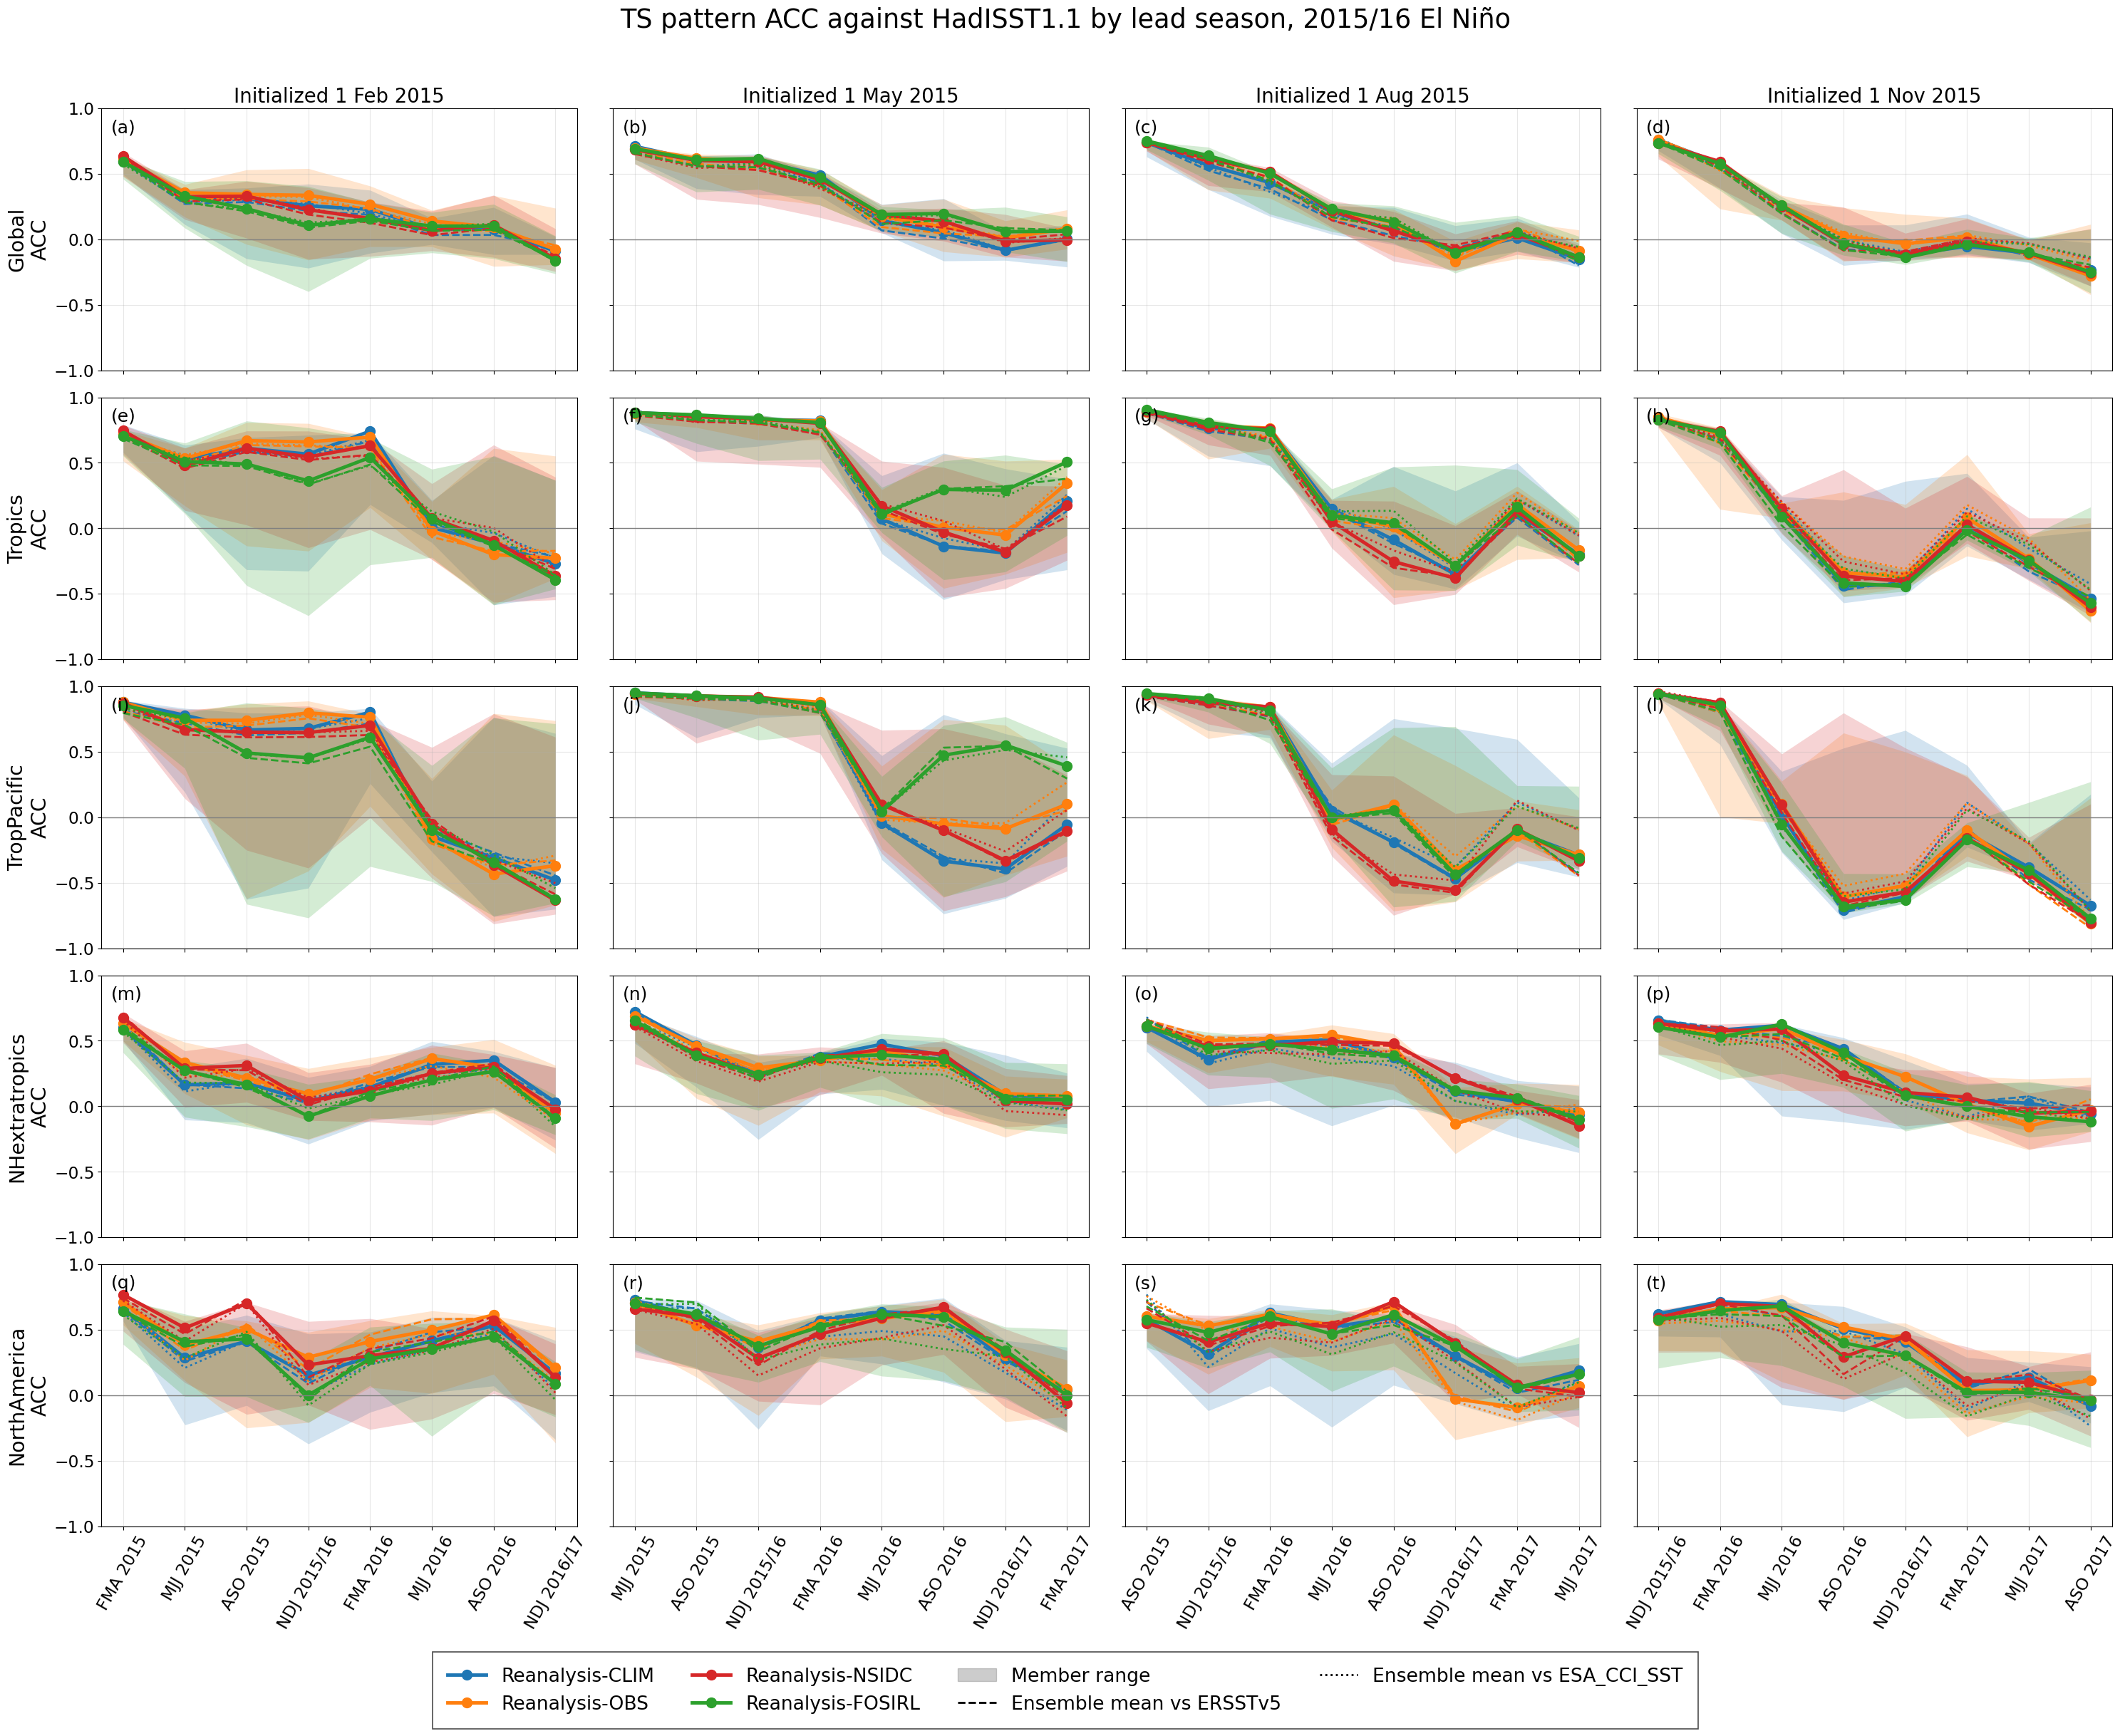

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/2_anomaly_maps_acc/figures/fig_rtenso2026_pattern_rmse_ts_y2015.png


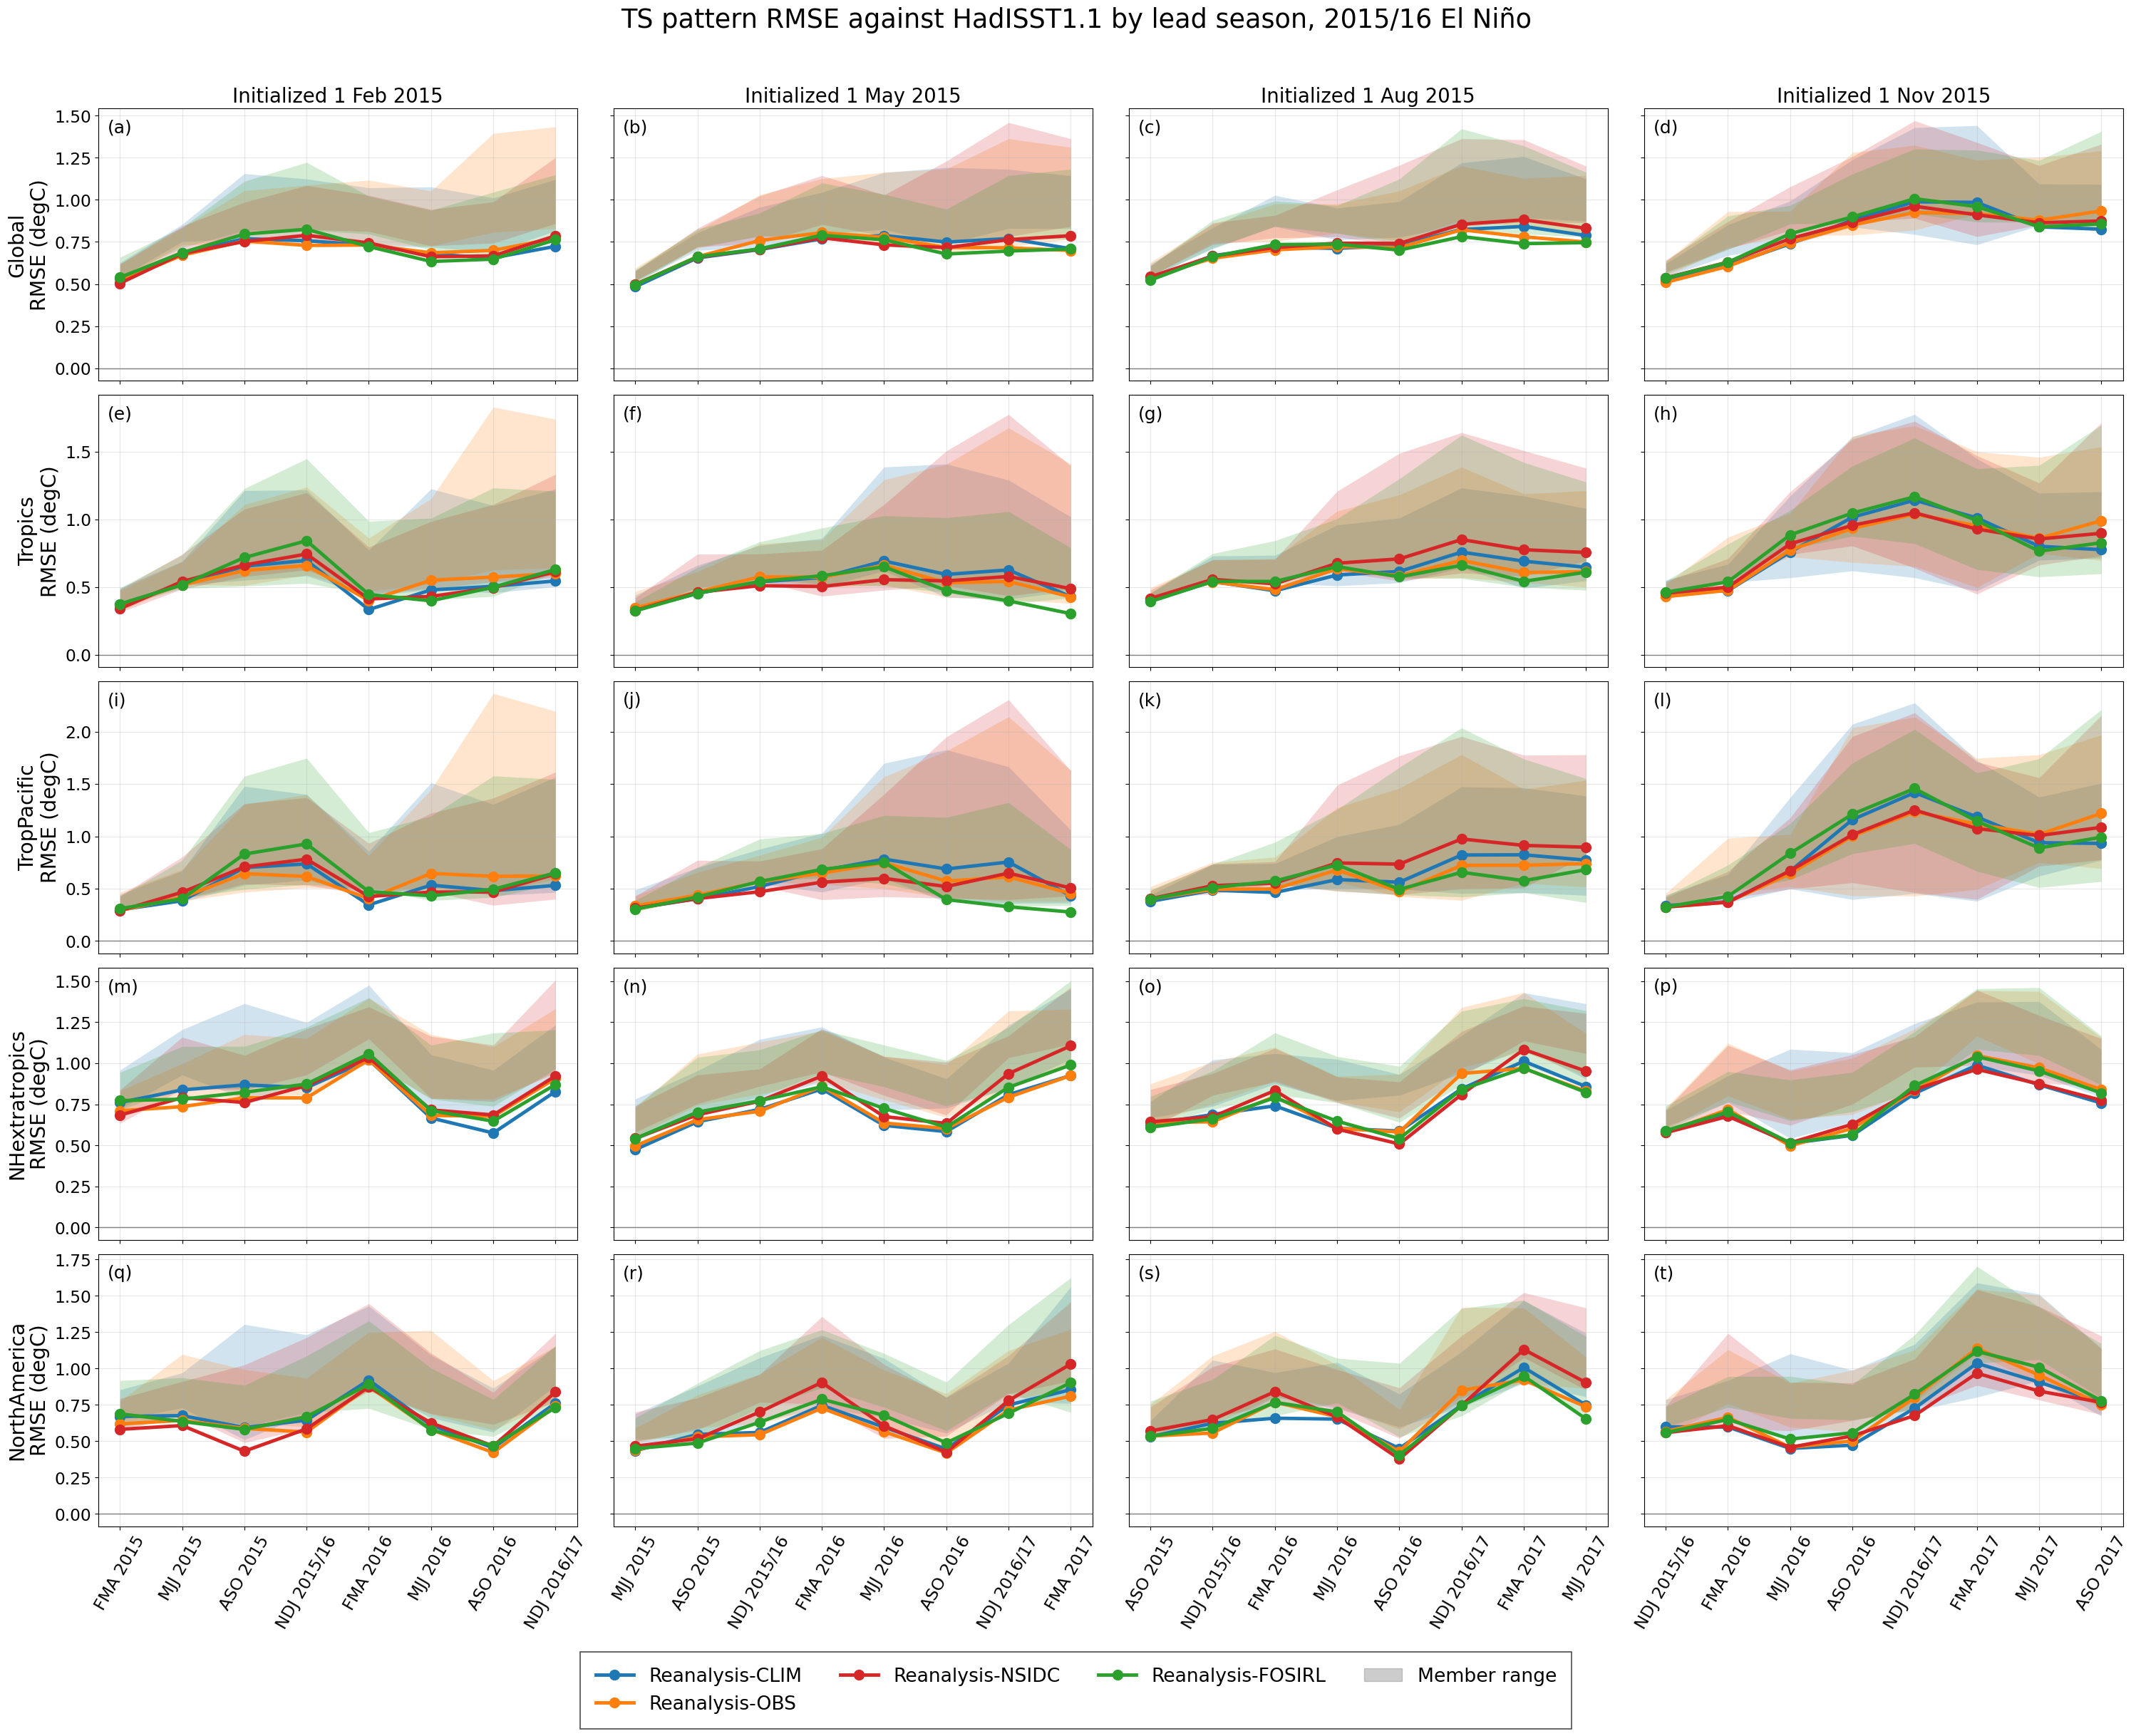

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/2_anomaly_maps_acc/figures/fig_rtenso2026_pattern_acc_ts_y2026.png


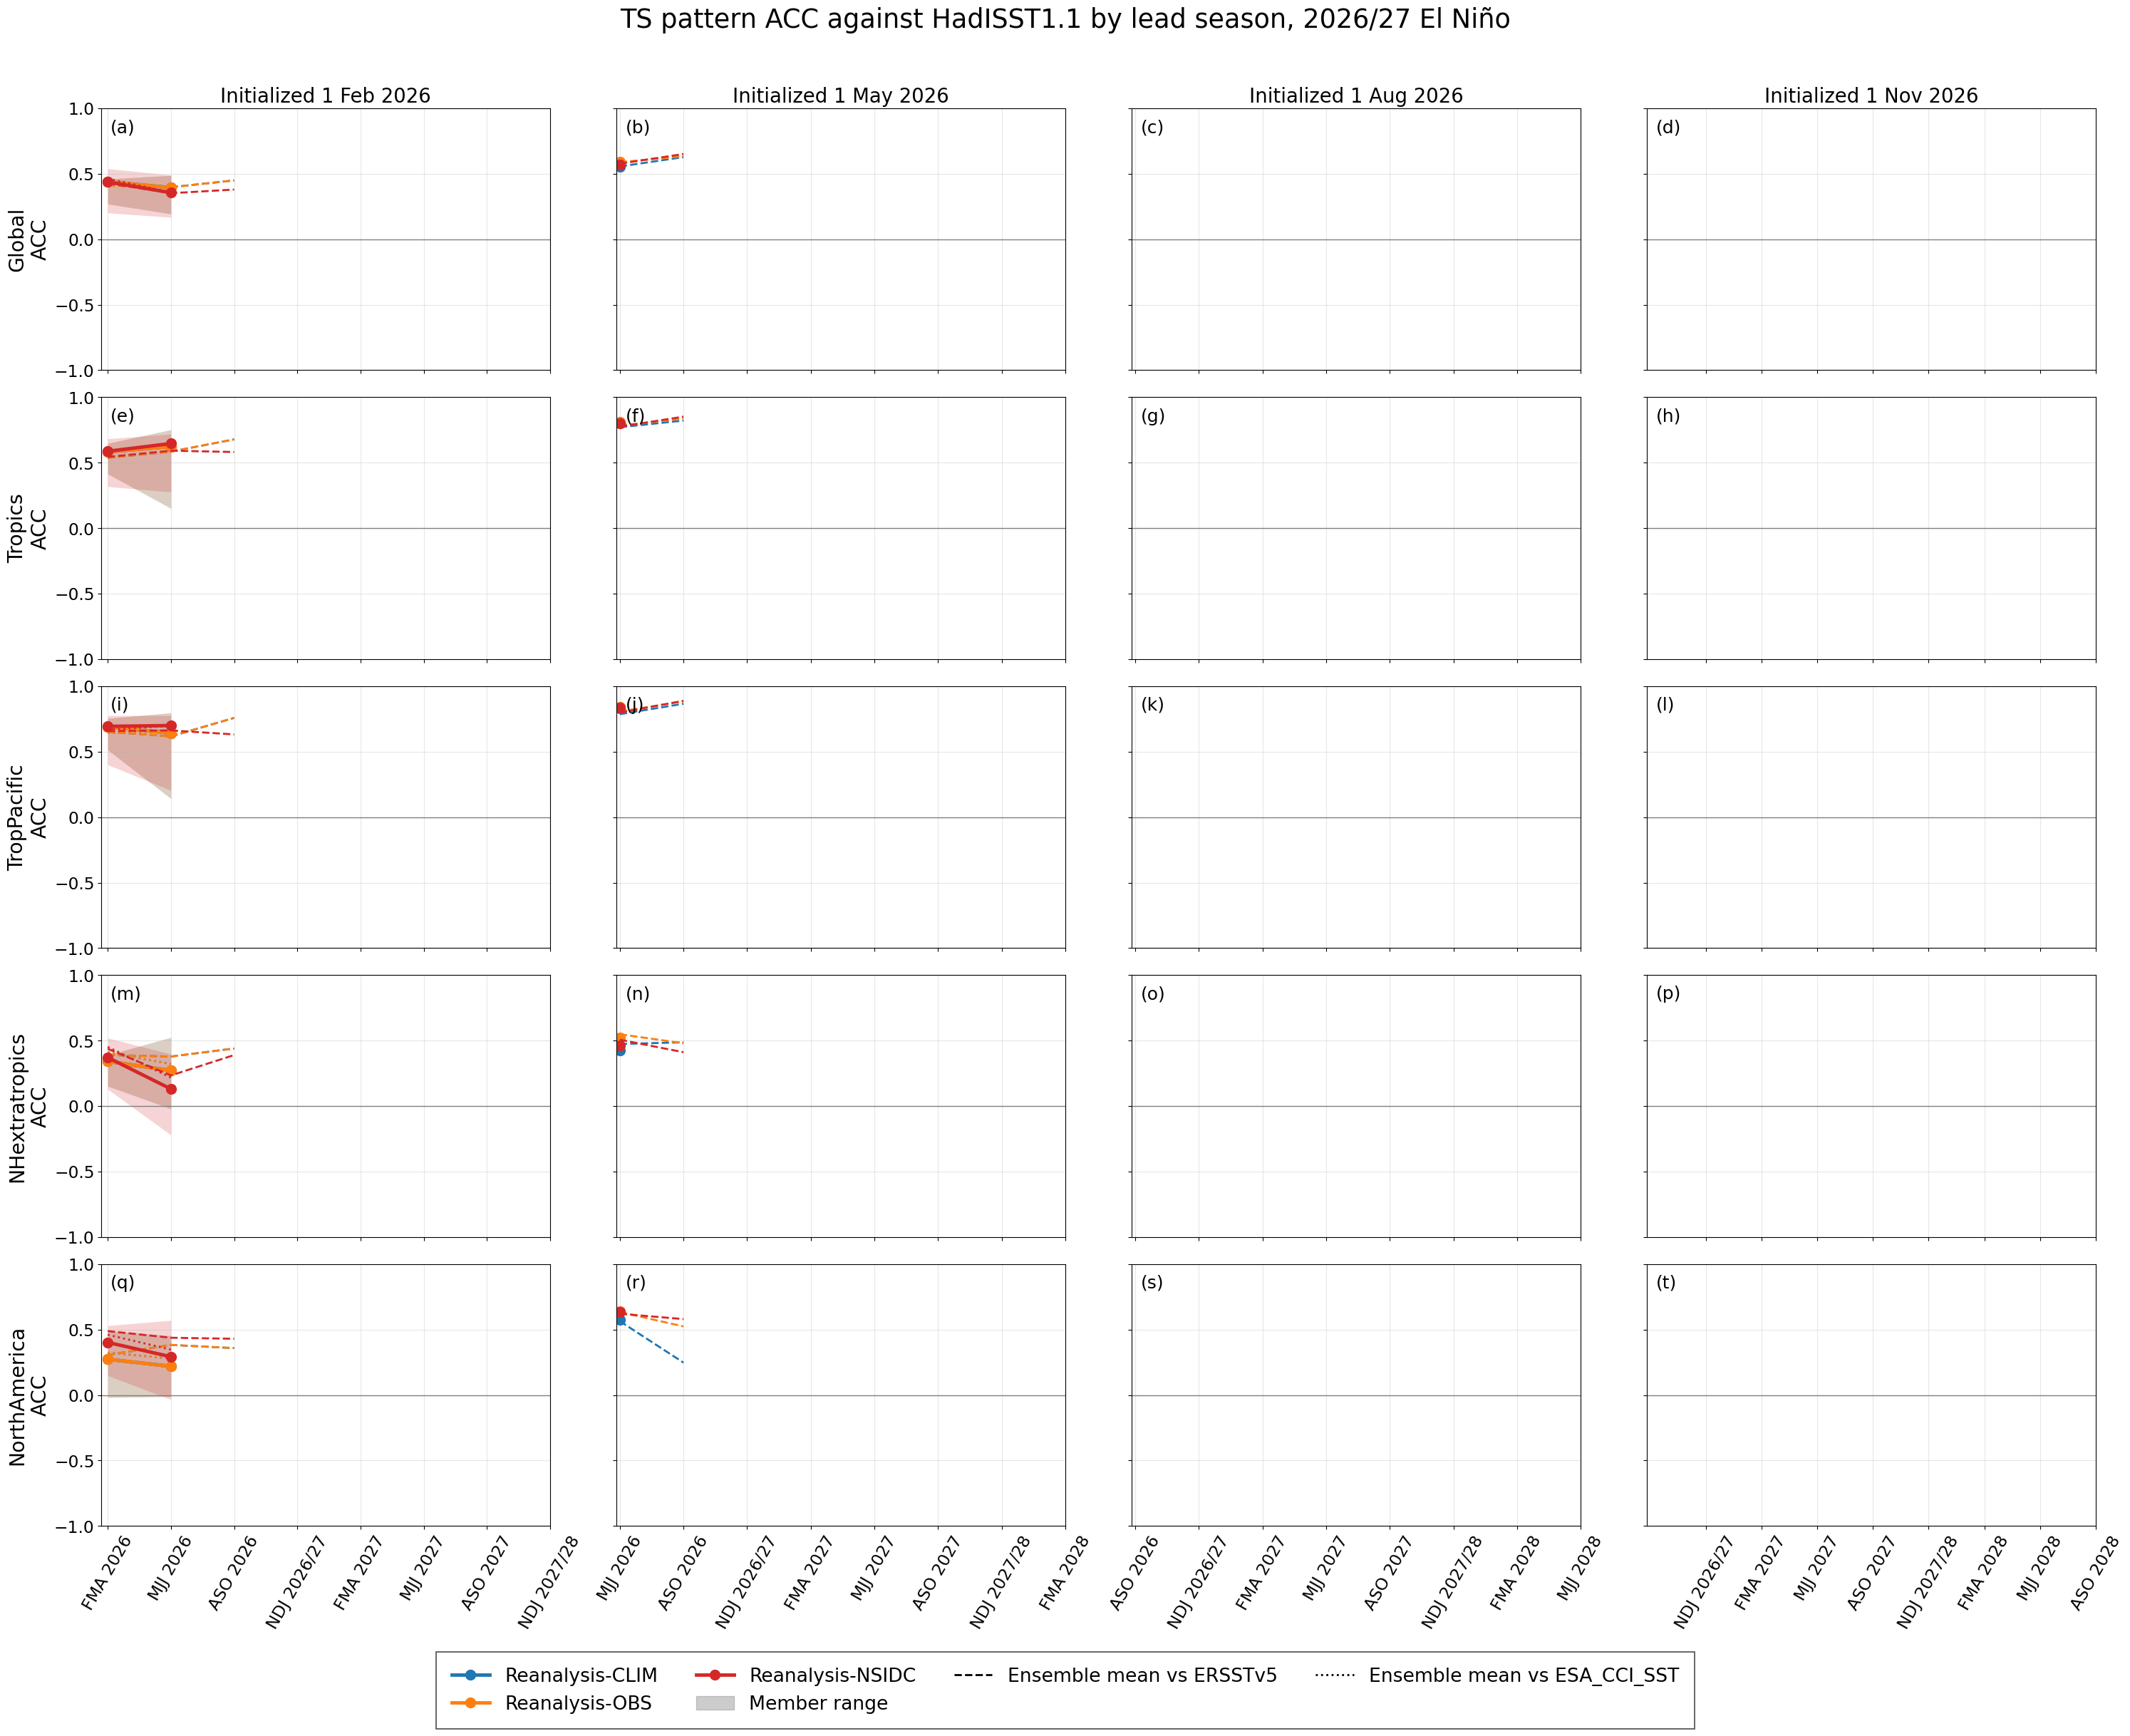

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/2_anomaly_maps_acc/figures/fig_rtenso2026_pattern_rmse_ts_y2026.png


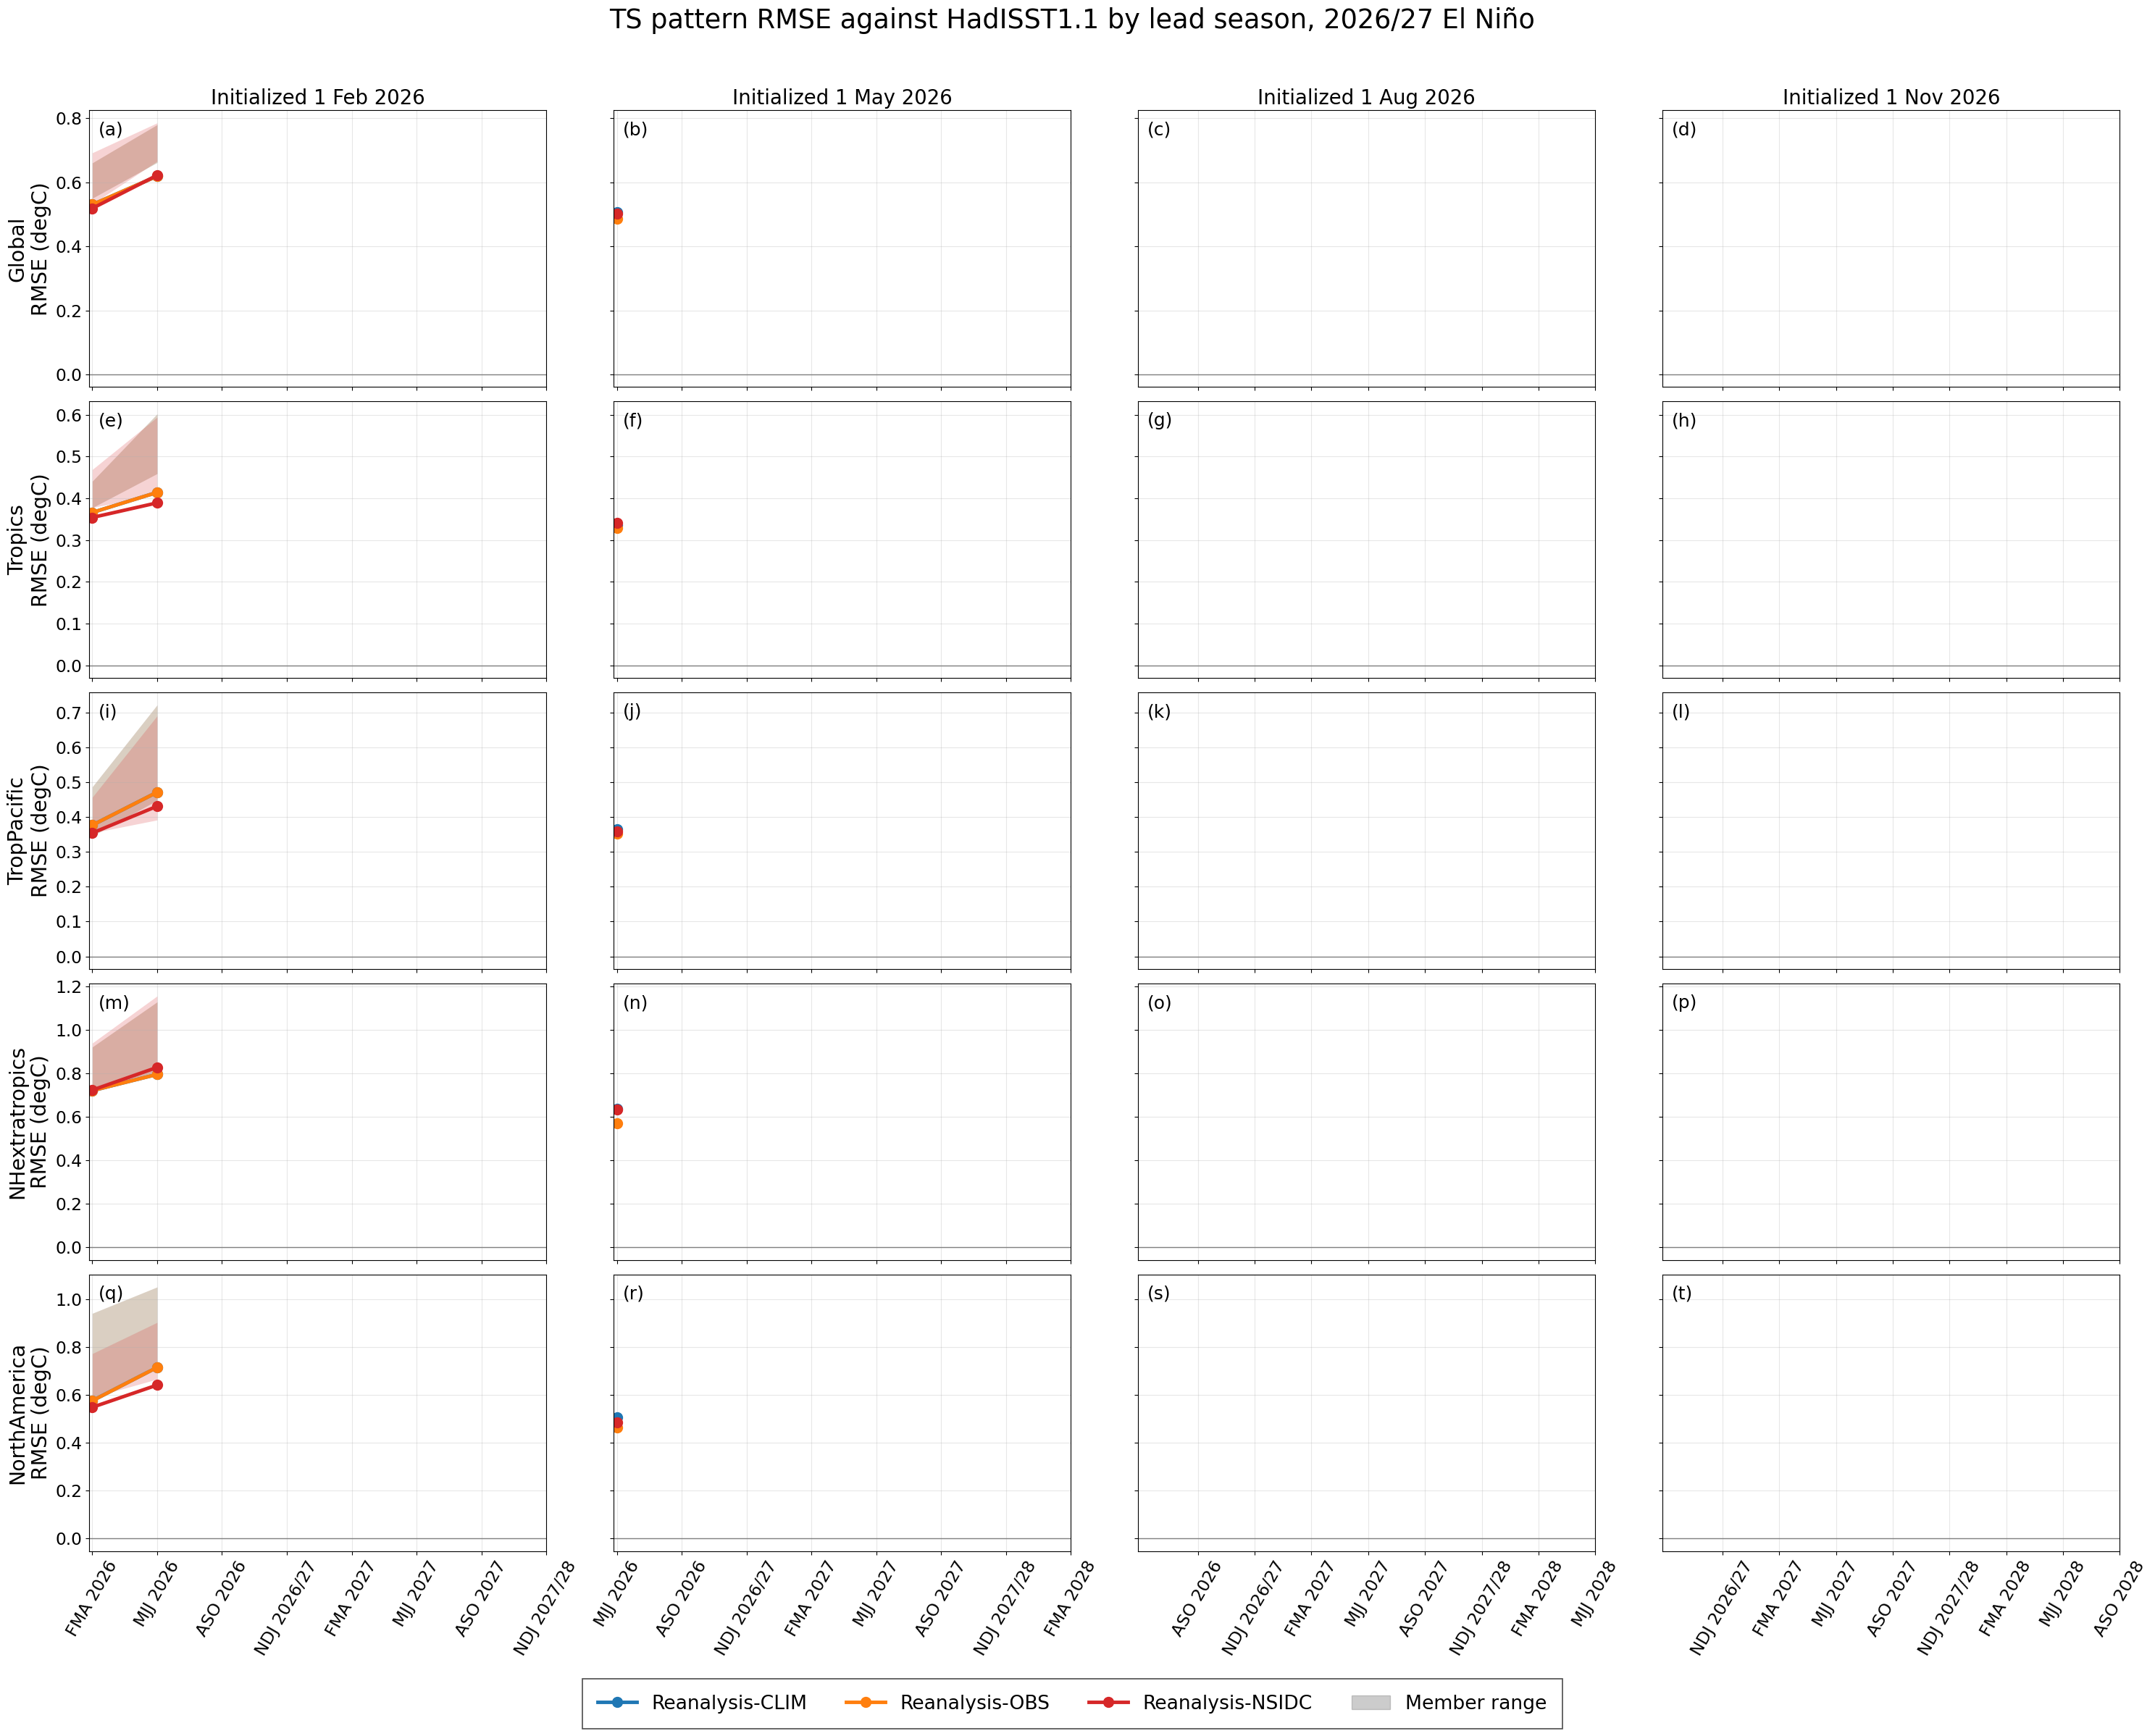

In [7]:
def plot_metric(name, ylabel, year, ylim=None):
    event = EVENTS[year]
    inits = [i for i in event["init_months"] if any((year, c, i) in metrics for c in CASES)]
    nrow, ncol = len(ACC_REGIONS), len(inits)
    fig, axes = plt.subplots(nrow, ncol, figsize=(FIG["metric_panel"][0] * ncol, FIG["metric_panel"][1] * nrow),
                             sharex="col", sharey="row" if ylim is None else True, squeeze=False)
    compare = OBS_COMPARE.get(FIELD, ()) if name == "acc" else ()
    for col, init in enumerate(inits):
        for row, region in enumerate(ACC_REGIONS):
            ax = axes[row, col]
            for case in CASES:
                ds = metrics.get((year, case, init))
                if ds is None:
                    continue
                color, season = CASES[case]["color"], ds["season"].values
                members = ds[f"{name}_member"].sel(region=region)
                ax.fill_between(season, members.min("member"), members.max("member"), color=color,
                                alpha=FIG["member_alpha"], lw=0)
                ax.plot(season, ds[f"{name}_ens"].sel(region=region), color=color, marker="o",
                        ms=FIG["marker_size"], lw=FIG["ens_lw"], label=case)
                for p in compare:
                    ax.plot(season, ds[f"acc_ens_{p}"].sel(region=region), color=color, ls=OBS_COMPARE_LS[p],
                            lw=FIG["compare_lw"])
            if ylim is not None:
                ax.set_ylim(*ylim)
            ax.axhline(0.0, color="0.5", lw=1.0)
            ax.grid(alpha=0.3)
            ax.tick_params(labelsize=FIG["tick"])
            ax.text(0.02, 0.96, f"({PANEL_LETTERS[row * ncol + col]})", transform=ax.transAxes, ha="left", va="top",
                    fontsize=FIG["title"])
            if col == 0:
                ax.set_ylabel(f"{region}\n{ylabel}", fontsize=FIG["label"])
            if row == 0:
                ax.set_title(f"Initialized 1 {MONTH_NAMES[init]} {year}", fontsize=FIG["title"] * 1.1)
            if row == nrow - 1:
                ds = next(metrics[(year, c, init)] for c in CASES if (year, c, init) in metrics)
                ax.set_xticks(ds["season"].values)
                ax.set_xticklabels([rc.target_season_label(t) for t in ds["time"].values], rotation=60,
                                   fontsize=FIG["tick"])
    handles = {l: h for ax in axes.flat for h, l in zip(*ax.get_legend_handles_labels())}
    handles["Member range"] = Patch(color="0.5", alpha=FIG["member_alpha"] * 2)
    for p in compare:
        handles[f"Ensemble mean vs {p}"] = Line2D([], [], color="k", ls=OBS_COMPARE_LS[p], lw=FIG["compare_lw"])
    fig.suptitle(f"{FIELD} pattern {name.upper()} against {obs[year].attrs['product']} by lead season, {event['label']}",
                 fontsize=FIG["suptitle"], y=FIG["suptitle_y"])
    fig.tight_layout()
    add_bottom_legend(fig, list(handles.values()), list(handles.keys()))
    return fig


for year in EVENTS:
    if not any(key[0] == year for key in metrics):
        continue
    fig = plot_metric("acc", "ACC", year, ylim=(-1.0, 1.0))
    save_fig(fig, "rtenso2026", "pattern_acc", FIELD, f"y{year}")
    plt.show()
    fig = plot_metric("rmse", f"RMSE ({rc.FIELDS[FIELD]['units']})", year)
    save_fig(fig, "rtenso2026", "pattern_rmse", FIELD, f"y{year}")
    plt.show()

In [8]:
table = []
for (year, case, init), ds in metrics.items():
    for s, t in zip(ds["season"].values, ds["time"].values):
        table.append({"year": year, "case": case, "start": MONTH_NAMES[init], "season": int(s),
                      "target": rc.target_season_label(t),
                      **{f"ACC_{r}": round(float(ds["acc_ens"].sel(region=r, season=s)), 3) for r in ACC_REGIONS}})
acc_table = pd.DataFrame(table)
acc_table.to_csv(OUTDIR / f"RTENSO2026_case_{FIELD}_pattern_acc.csv", index=False)
acc_table.dropna(subset=["ACC_Global"]).pivot_table(index=["year", "start", "season", "target"], columns="case",
                                                    values="ACC_Global")

case                           Reanalysis-CLIM  Reanalysis-FOSIRL  \
year start season target                                            
2015 Aug   1      ASO 2015               0.738              0.752   
           2      NDJ 2015/16            0.565              0.639   
           3      FMA 2016               0.432              0.502   
           4      MJJ 2016               0.210              0.231   
           5      ASO 2016               0.068              0.132   
           6      NDJ 2016/17           -0.096             -0.104   
           7      FMA 2017               0.010              0.053   
           8      MJJ 2017              -0.153             -0.137   
     Feb   1      FMA 2015               0.595              0.592   
           2      MJJ 2015               0.318              0.330   
           3      ASO 2015               0.312              0.234   
           4      NDJ 2015/16            0.255              0.106   
           5      FMA 2016               0.229              0.156   
           6      MJJ 2016               0.078              0.101   
           7      ASO 2016               0.077              0.100   
           8      NDJ 2016/17           -0.090             -0.162   
     May   1      MJJ 2015               0.710              0.692   
           2      ASO 2015               0.604              0.607   
           3      NDJ 2015/16            0.599              0.616   
           4      FMA 2016               0.490              0.471   
           5      MJJ 2016               0.144              0.189   
           6      ASO 2016               0.051              0.197   
           7      NDJ 2016/17           -0.085              0.058   
           8      FMA 2017               0.002              0.062   
     Nov   1      NDJ 2015/16            0.757              0.735   
           2      FMA 2016               0.580              0.578   
           3      MJJ 2016               0.249              0.259   
           4      ASO 2016              -0.038             -0.030   
           5      NDJ 2016/17           -0.121             -0.140   
           6      FMA 2017              -0.053             -0.041   
           7      MJJ 2017              -0.106             -0.100   
           8      ASO 2017              -0.238             -0.250   
2026 Feb   1      FMA 2026               0.439                NaN   
           2      MJJ 2026               0.394                NaN   
     May   1      MJJ 2026               0.554                NaN   

case                           Reanalysis-NSIDC  Reanalysis-OBS  
year start season target                                         
2015 Aug   1      ASO 2015                0.739           0.739  
           2      NDJ 2015/16             0.613           0.621  
           3      FMA 2016                0.514           0.513  
           4      MJJ 2016                0.219           0.223  
           5      ASO 2016                0.063           0.128  
           6      NDJ 2016/17            -0.079          -0.168  
           7      FMA 2017                0.037           0.040  
           8      MJJ 2017               -0.136          -0.086  
     Feb   1      FMA 2015                0.636           0.612  
           2      MJJ 2015                0.325           0.356  
           3      ASO 2015                0.329           0.343  
           4      NDJ 2015/16             0.226           0.335  
           5      FMA 2016                0.159           0.267  
           6      MJJ 2016                0.066           0.140  
           7      ASO 2016                0.110           0.093  
           8      NDJ 2016/17            -0.150          -0.076  
     May   1      MJJ 2015                0.684           0.697  
           2      ASO 2015                0.602           0.618  
           3      NDJ 2015/16             0.591           0.593  
           4      FMA 2016                0.455           0.